# Fig 2 · Index cost

* **A** storage of every index, with the folds whole → Spindle-naive and Spindle-naive → Spindle.
* **B** build time of Spindle-naive (file loading excluded) and the seconds each other index adds to it.
* **C** build time against the number of cells (tonsil, subsampled): Spindle-naive and all four indexes, with a
  line growing in proportion to the cells from the smallest subsample.

Mean ± s.d. over seeds 0–4 in A and B. The dataset table, the peak memory and the storage, memory and gene ladders
are appendix material (old notebook: `experiments/figures/_backup_2026-11-01/F2_cost.ipynb`).

**Run first:** `R0_index_cache` → `R1_index_cost` (reads `results/index_cost/builds.csv` and `ladder.csv`).
Writes `figures/fig2_cost/panels/{A,B,C,legend}.{pdf,png}` and `figures/fig2_cost/fig2_cost.{pdf,png}`.

In [1]:
import math
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

import style as ps

FIG = "fig2_cost"
RES = ROOT / "results" / "index_cost"
ORDER = ps.DATASET_ORDER
TC = ps.TIER_COLORS

b = pd.read_csv(RES / "builds.csv")
b["naive_build_s"] = b[["prepare_s", "layout_s", "naive_s"]].sum(axis=1)
b["key"] = pd.Categorical(b["key"], ORDER, ordered=True)
b = b.sort_values(["key", "seed"])
lad = pd.read_csv(RES / "ladder.csv")
print(sorted(set(b.tag)), sorted(set(lad.tag)))

# one row (mm): A and B share the height and vertical margins, so the dataset rows line up
H, TOP, BOTTOM = 54.0, 2.5, 13.0
ROW_OFF = 0.17  # the two storage rows of a dataset
STORAGE_XLIM = (0.7, 8000.0)  # MB
W_A, W_B, W_C = 70.0, 52.0, 56.0
LABEL_W = 20.0  # dataset labels of A


def box(fig, x, y, w, h):
    """Axes occupying the w x h mm box at (x, y) mm from the panel's top-left corner."""
    W, H_ = ps.size_mm(fig)
    return ps.axes(fig, left=x, top=y, right=W - x - w, bottom=H_ - y - h)


def rows(ax):
    n = len(ORDER)
    ax.set_ylim(n - 0.5, -0.5)
    ax.set_yticks(range(n))
    return n


def mean_sd(col):
    g = b.groupby("key", observed=True)[col]
    return g.mean().to_numpy(), g.std().to_numpy()


def marker(ax, x, y, tier, mk, filled=True, xerr=None, ms=3.2):
    k = TC[tier]
    ax.errorbar(x, y, xerr=xerr, fmt=mk, ms=ms, color=k, mfc=k if filled else "white", mec=k, mew=0.8,
                elinewidth=0.6, zorder=3)


def row_axis(ax):
    ax.set_yticklabels([])
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)

['method-v2'] ['method-v2']


## A · Storage (fold labels: whole → Spindle-naive, Spindle-naive → Spindle, of the means over seeds)

figures/fig2_cost/panels/A.pdf/.png: 70 x 54 mm, 0.0 / 0.3 MB


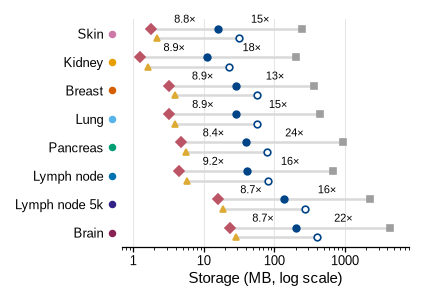

In [2]:
def fold_label(f):
    return f"{f:.0f}×" if f >= 10 else f"{f:.1f}×"


def panel_a(fig):
    ax = box(fig, LABEL_W, TOP, W_A - LABEL_W - 1.5, H - TOP - BOTTOM)
    n = rows(ax)
    y = np.arange(n)
    up, lo = y - ROW_OFF, y + ROW_OFF
    mb = {c: tuple(v / 1e6 for v in mean_sd(f"bytes_{c}"))
          for c in ("whole", "naive", "spindle", "naive_partial", "spindle_partial")}
    for yy, a, c in ((up, "whole", "spindle"), (lo, "naive_partial", "spindle_partial")):
        ax.hlines(yy, mb[c][0], mb[a][0], color=ps.LIGHT, lw=1.2, zorder=1)
    for c, yy, tier, mk, filled in (("whole", up, "whole", "s", True), ("naive", up, "naive", "o", True),
                                    ("spindle", up, "spindle", "D", True), ("naive_partial", lo, "naive", "o", False),
                                    ("spindle_partial", lo, "spindle_partial", "^", True)):
        marker(ax, mb[c][0], yy, tier, mk, filled, xerr=mb[c][1])
    for i in range(n):  # folds at the log midpoints, above the whole-tile row
        for a, c in (("naive", "whole"), ("spindle", "naive")):
            xm = math.sqrt(mb[a][0][i] * mb[c][0][i])
            ax.text(xm, up[i] - 0.13, fold_label(mb[c][0][i] / mb[a][0][i]), ha="center", va="bottom", fontsize=5.5)
    ax.set_xscale("log")
    ps.plain_log(ax, "x", subs=(1.0,))
    ps.log_grid(ax, "x")
    ax.set_xlim(*STORAGE_XLIM)
    ax.set_xlabel("Storage (MB, log scale)")
    ax.set_yticklabels([ps.DATASET_LABELS[k] for k in ORDER])
    ax.tick_params(axis="y", length=0, pad=9)
    ax.spines["left"].set_visible(False)
    for i, k in enumerate(ORDER):  # the dataset's colour, as in every other figure
        ax.plot(-0.035, i, "o", ms=2.6, color=ps.DATASET_COLORS[k], clip_on=False, transform=ax.get_yaxis_transform())


fig = ps.panel(W_A, H); panel_a(fig); ps.save_panel(fig, FIG, "A")

## B · Build time: Spindle-naive's full build (file loading excluded), and what each other index adds to it

figures/fig2_cost/panels/B.pdf/.png: 52 x 54 mm, 0.0 / 0.2 MB


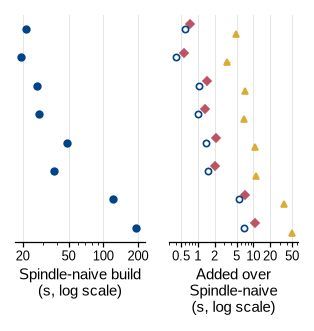

In [3]:
def panel_b(fig):
    y = np.arange(len(ORDER))
    w = W_B / 2
    axs = []
    for j, xlabel in enumerate(("Spindle-naive build\n(s, log scale)", "Added over\nSpindle-naive\n(s, log scale)")):
        ax = box(fig, j * w + 2.0, TOP, w - 4.0, H - TOP - BOTTOM)
        rows(ax)
        ax.set_xscale("log")
        ps.log_grid(ax, "x")
        ax.set_xlabel(xlabel)
        row_axis(ax)
        axs.append(ax)
    mu, sd = mean_sd("naive_build_s")
    marker(axs[0], mu, y, "naive", "o", xerr=sd)
    for col, tier, mk, filled, dy in (("spindle_s", "spindle", "D", True, -ROW_OFF),
                                      ("naive_partial_s", "naive", "o", False, 0.0),
                                      ("spindle_partial_s", "spindle_partial", "^", True, ROW_OFF)):
        mu, sd = mean_sd(col)
        marker(axs[1], mu, y + dy, tier, mk, filled, xerr=sd, ms=3.0)
    for ax in axs:
        ps.plain_log(ax, "x", subs=(1.0, 2.0, 5.0))


fig = ps.panel(W_B, H); panel_b(fig); ps.save_panel(fig, FIG, "B")

## C · Build time against the number of cells (tonsil, subsampled)

Spindle-naive's full build (blue) and the build of all four indexes (black), file loading excluded. The dotted line
grows in proportion to the number of cells from the smallest subsample.

figures/fig2_cost/panels/C.pdf/.png: 56 x 54 mm, 0.0 / 0.2 MB


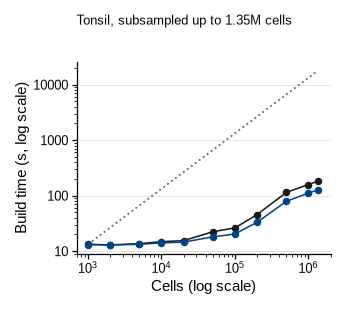

In [4]:
LINEAR = ps.MUTED


def panel_c(fig):
    d = lad[lad.ladder == "cells"].sort_values("n_cells")
    full = d.iloc[-1]
    ax = box(fig, 11.0, TOP + 6.0, W_C - 13.0, H - TOP - 6.0 - BOTTOM)
    x = d.n_cells.to_numpy(float)
    ax.plot(x, d.build_s.iloc[0] * x / x[0], ls=":", lw=0.9, color=LINEAR, zorder=2)
    ax.plot(x, d.build_s, marker="o", ms=2.6, color=ps.INK, zorder=3)
    k = TC["naive"]
    ax.plot(x, d.naive_build_s, marker="o", ms=2.6, color=k, zorder=4)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ps.plain_log(ax, "x", subs=(1.0,))
    ps.plain_log(ax, "y", subs=(1.0,))
    ps.log_grid(ax, "y")
    ax.set_xlim(7e2, 2e6)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _p: f"$10^{{{round(math.log10(v))}}}$"))
    ax.set_xlabel("Cells (log scale)")
    ax.set_ylabel("Build time (s, log scale)")
    W, _ = ps.size_mm(fig)
    fig.text(11.0 / W, 1 - 0.5 / H, f"Tonsil, subsampled up to {full.n_cells / 1e6:.2f}M cells",
             fontsize=ps.TICK_PT, va="top")


fig = ps.panel(W_C, H); panel_c(fig); ps.save_panel(fig, FIG, "C")

## Legend (shared by A–C)

In [5]:
def panel_legend(fig):
    def h(tier, mk, label, filled=True):
        k = TC[tier]
        return Line2D([], [], ls="", marker=mk, ms=3.5, color=k, mfc=k if filled else "white", mec=k, mew=0.8,
                      label=label)

    handles = [h("whole", "s", "Whole covariances"), h("naive", "o", "Spindle-naive"), h("spindle", "D", "Spindle"),
               h("naive", "o", "Spindle-naive (gene sets)", filled=False),
               h("spindle_partial", "^", "Spindle (gene sets)"),
               Line2D([], [], marker="o", ms=2.6, color=ps.INK, label="All four indexes"),
               Line2D([], [], ls=":", lw=0.9, color=LINEAR, label="Linear in cells")]
    fig.legend(handles=handles, ncol=7, loc="center", columnspacing=0.9)


fig = ps.panel(180, 5); panel_legend(fig); ps.save_panel(fig, FIG, "legend")

figures/fig2_cost/panels/legend.pdf/.png: 180 x 5 mm, 0.0 / 0.1 MB


<Figure size 1062.99x29.5276 with 0 Axes>

## Full figure

figures/fig2_cost/fig2_cost.pdf/.png: 180 x 63 mm, 0.0 / 0.8 MB


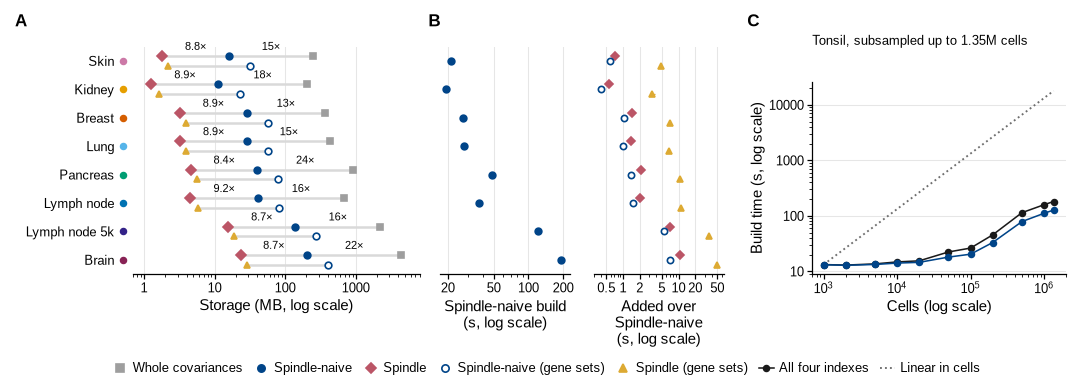

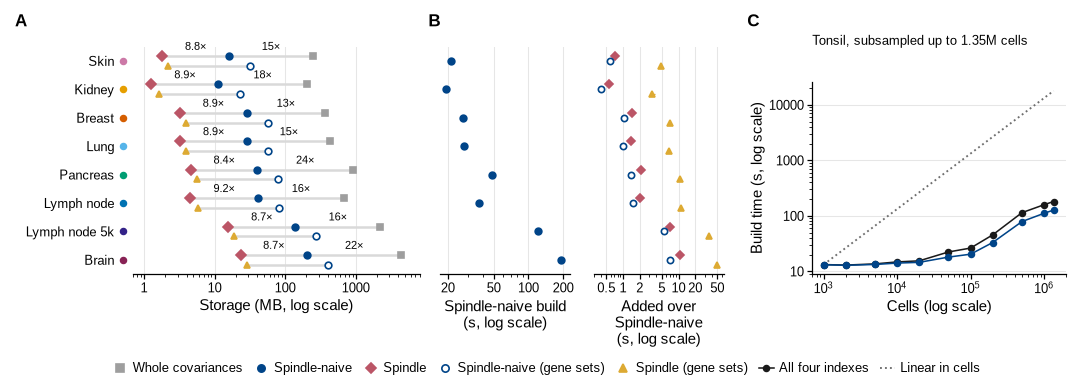

In [6]:
Y = 3.0
page = ps.page(180, Y + H + 6.0)
panel_a(ps.place(page, "A", 0, Y, W_A, H, dy=-3.0))
panel_b(ps.place(page, "B", W_A, Y, W_B, H, dy=-3.0))
panel_c(ps.place(page, "C", W_A + W_B + 2.0, Y, W_C, H, dy=-3.0))
panel_legend(ps.place(page, None, 0, Y + H + 0.5, 180, 5))
ps.save_figure(page, FIG)
page